# Network Analysis with Python and NetworkX: A Beginner's Tutorial

*Originally adapted from [Analytics Vidhya: Introduction to Graph Theory and Network Analysis](https://www.analyticsvidhya.com/blog/2018/04/introduction-to-graph-theory-network-analysis-python-codes/); expanded and rewritten for students with no programming or network-analysis background.*

By the end of this notebook you will be able to:

1. explain what a **network** (also called a **graph**) is, and the difference between **undirected** and **directed** networks;
2. build, inspect, and modify a network in Python using the **NetworkX** library;
3. draw networks in several different ways;
4. calculate **by hand** and **with code** five core measures (in-degree, out-degree, degree centrality, betweenness centrality, and closeness centrality), and explain what each one tells you;
5. apply those measures to a real social network.

You don't need any prior programming experience. Every code cell is explained, and Section 1 is a short Python primer.

## How to use this notebook

A Jupyter notebook is a document made of **cells**:

* **Text cells** (like this one) contain explanations.
* **Code cells** (grey boxes, marked `In [ ]:`) contain Python code. To run one, click on it and press **Shift + Enter**. The output appears directly below the cell.

A few tips:

* Run the cells **in order, from top to bottom**. Later cells often depend on earlier ones.
* If something behaves strangely, use **Kernel → Restart & Run All** (or **Run → Run All Cells**) to start fresh.
* You can't break anything. Feel free to change numbers or names in the code and re-run cells to see what happens. Experimenting is the best way to learn.
* Lines starting with `#` inside code are **comments**: notes for humans that Python ignores.

### Contents
0. What is a network?
1. Just enough Python
2. Building your first network
3. Looking inside a network: nodes, edges, neighbours, attributes
4. Building networks from tables, and graph operations
5. Many ways to draw a network
6. Directed networks: in-degree and out-degree
7. Degree centrality
8. Paths and distances (the foundation for the next two measures)
9. Betweenness centrality
10. Closeness centrality
11. Putting it all together on a real network
12. Summary, glossary, exercises

## 0. What is a network?

A **network** (mathematicians say **graph**) is a way to describe *things* and the *connections* between them.

* The things are called **nodes** (or *vertices*). They are drawn as dots or circles.
* The connections are called **edges** (or *links*, or *ties*). They are drawn as lines between nodes.

Networks are everywhere:

| Network | Nodes | Edges |
|---|---|---|
| Friendship network | people | "are friends" |
| Instagram / X | accounts | "follows" |
| Airline network | airports | direct flights |
| The web | web pages | hyperlinks |
| Citation network | research papers | "cites" |
| Food web | species | "eats" |

### Undirected vs. directed

* In an **undirected** network, an edge goes both ways. If Ana is friends with Ben, Ben is friends with Ana. We draw a plain line: `Ana —— Ben`.
* In a **directed** network, each edge has a direction, drawn as an arrow. If Ana follows Ben on Instagram, Ben doesn't necessarily follow Ana: `Ana ──▶ Ben`.

This difference matters a lot. As we'll see, *in-degree* and *out-degree* only make sense for directed networks.

### Why analyse networks?

Network analysis lets us answer questions such as:

* *Who is the most popular person?* → degree, in-degree
* *Who is the gatekeeper that information has to pass through?* → betweenness centrality
* *Who can spread a rumour to everyone fastest?* → closeness centrality

The rest of this notebook teaches you how to compute these, both by hand and with Python.

## 1. Just enough Python

You only need a handful of Python ideas for this tutorial. Run each cell below and read its output.

**Variables** store values under a name, using `=`.

In [1]:
# A variable is a name for a value
number_of_friends = 3
person = "Ana"          # text must be in quotes; text is called a "string"

print(person, "has", number_of_friends, "friends")

Ana has 3 friends


**Lists** hold several values in order, inside square brackets `[ ]`. **Tuples** are like lists but written with round brackets `( )`. We'll use a tuple of two names to represent one edge.

In [2]:
people = ["Ana", "Ben", "Cai"]      # a list
friendship = ("Ana", "Ben")         # a tuple: one edge between Ana and Ben

print(people)
print("The first person in the list is", people[0])   # Python counts from 0!
print("This edge connects", friendship[0], "and", friendship[1])

['Ana', 'Ben', 'Cai']
The first person in the list is Ana
This edge connects Ana and Ben


**Dictionaries** store *key → value* pairs inside curly brackets `{ }`. NetworkX often returns its results as dictionaries, for example `{"Ana": 2, "Ben": 3}` meaning "Ana has 2, Ben has 3".

In [3]:
ages = {"Ana": 19, "Ben": 20, "Cai": 21}   # a dictionary
print("Ben is", ages["Ben"])                 # look up a value by its key

Ben is 20


**Loops** repeat an action for every item in a collection. The indented lines run once per item.

In [4]:
for name, age in ages.items():
    print(name, "is", age, "years old")

Ana is 19 years old
Ben is 20 years old
Cai is 21 years old


**Libraries, functions, and methods.** A *library* is a toolbox of code someone else wrote. We load one with `import`. We then use its tools with a dot: `nx.Graph()` means "the `Graph` tool from the `nx` toolbox". A *method* is a tool attached to an object, like `G.add_node(...)`, which means "add a node to `G`".

That's all the Python you need. Let's load the libraries we'll use:

* **NetworkX** (`nx`) for building and analysing networks;
* **Matplotlib** (`plt`) for drawing;
* **pandas** (`pd`) for tables.

If you get an error like `ModuleNotFoundError`, install the libraries first by running `pip install networkx matplotlib pandas scipy` in a terminal (or `%pip install networkx matplotlib pandas scipy` in a code cell).

In [5]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (7, 5)   # default size of figures, in inches
print("NetworkX version:", nx.__version__)

NetworkX version: 3.6.1


## 2. Building your first network

### 2.1 An empty graph

`nx.Graph()` creates an empty **undirected** network. We store it in a variable called `G` (a traditional name for a graph).

In [6]:
G = nx.Graph()   # an empty, undirected graph
print(G)         # print a short description

Graph with 0 nodes and 0 edges


### 2.2 Adding nodes

* `G.add_node(x)` adds **one** node.
* `G.add_nodes_from([...])` adds **several** nodes from a list.

Nodes can be almost anything: numbers, names, and so on. Here we start with numbers.

In [7]:
G.add_node(1)              # add one node
G.add_nodes_from([2, 3])   # add several nodes at once

print("Nodes:", list(G.nodes()))
print(G)

Nodes: [1, 2, 3]
Graph with 3 nodes and 0 edges


### 2.3 Adding edges

* `G.add_edge(a, b)` adds one edge between nodes `a` and `b`.
* `G.add_edges_from([...])` adds several edges from a list of pairs.

Two details are worth knowing:

* In an undirected graph, adding an edge that already exists does nothing. `(1, 2)` and `(2, 1)` are the same edge, so you can't accidentally get duplicates.
* If you add an edge to a node that doesn't exist yet, NetworkX **creates the node automatically**.

In [8]:
G.add_edge(1, 2)                       # one edge

e = (2, 3)                             # an edge stored in a tuple...
G.add_edge(*e)                         # ...the * "unpacks" the tuple into two arguments: same as G.add_edge(2, 3)

G.add_edges_from([(1, 2), (1, 3)])     # several edges; (1, 2) already exists, so only (1, 3) is new

print("Edges:", list(G.edges()))
print(G)

Edges: [(1, 2), (1, 3), (2, 3)]
Graph with 3 nodes and 3 edges


### 2.4 A first picture

`nx.draw(G)` draws the graph. `with_labels=True` shows the node names. We'll explore drawing much more in Section 5.

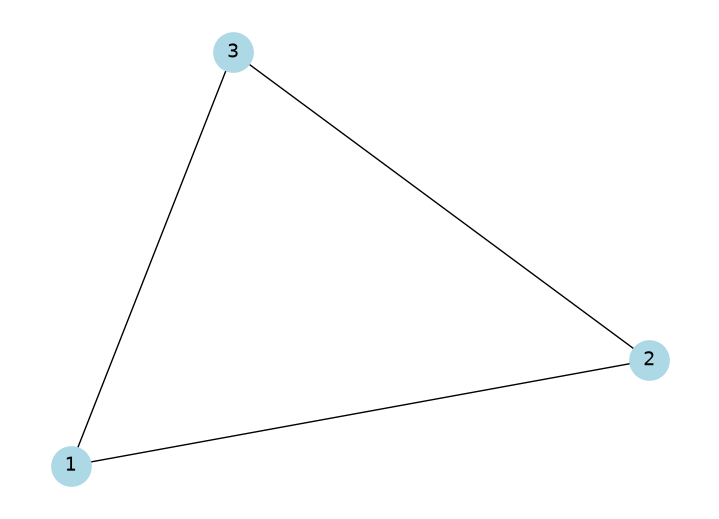

In [9]:
nx.draw(G, with_labels=True, node_color="lightblue", node_size=800, font_size=14)
plt.show()

### 2.5 Removing things

`G.remove_edge(a, b)` and `G.remove_node(x)` delete things. Removing a node also removes every edge attached to it. We'll make a copy first, so our original `G` stays intact.

In [10]:
H = G.copy()          # work on a copy so G is unchanged
H.remove_edge(1, 3)
print("After removing edge (1, 3):", list(H.edges()))
H.remove_node(2)
print("After removing node 2:     ", list(H.nodes()), "edges:", list(H.edges()))
print("The original G is unchanged:", list(G.edges()))

After removing edge (1, 3): [(1, 2), (2, 3)]
After removing node 2:      [1, 3] edges: []
The original G is unchanged: [(1, 2), (1, 3), (2, 3)]


## 3. Looking inside a network

### 3.1 Nodes, edges, and counts

In [11]:
print("Nodes:", G.nodes())
print("Edges:", G.edges())
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Nodes: [1, 2, 3]
Edges: [(1, 2), (1, 3), (2, 3)]
Number of nodes: 3
Number of edges: 3


### 3.2 Neighbours

Two nodes are **neighbours** (or *adjacent*) if an edge connects them. `G[1]` (the same as `G.adj[1]`) shows the neighbours of node 1. `list(G.neighbors(1))` gives just the list of names.

In [12]:
print("G[1] =", G[1])
print("Neighbours of node 1:", list(G.neighbors(1)))

G[1] = {2: {}, 3: {}}
Neighbours of node 1: [2, 3]


The output `{2: {}, 3: {}}` is a dictionary: *neighbour → information about the edge*. The `{}` are **empty**, because we haven't stored any information on the edges yet. That is also why `G[1][2]` and `G.edges[1, 2]` both return `{}`: they ask for the information stored on the edge between 1 and 2.

In [13]:
print("G[1][2]       =", G[1][2])
print("G.edges[1, 2] =", G.edges[1, 2])

G[1][2]       = {}
G.edges[1, 2] = {}


### 3.3 Attributes: storing information on nodes and edges

Real networks carry extra information, such as a person's name, or how strong a friendship is. These are called **attributes**, and you can attach any you like.

In [14]:
# Edge attributes
G.edges[1, 2]["weight"] = 4                 # e.g. "1 and 2 met 4 times"
G.add_edge(2, 3, weight=1, kind="coworkers")  # attributes can be set while adding an edge

# Node attributes
G.nodes[1]["name"] = "Ana"
G.nodes[2]["name"] = "Ben"
G.nodes[3]["name"] = "Cai"

print("G.edges[1, 2] now =", G.edges[1, 2])
print("All edges with their data:", list(G.edges(data=True)))
print("All nodes with their data:", list(G.nodes(data=True)))

G.edges[1, 2] now = {'weight': 4}
All edges with their data: [(1, 2, {'weight': 4}), (1, 3, {}), (2, 3, {'weight': 1, 'kind': 'coworkers'})]
All nodes with their data: [(1, {'name': 'Ana'}), (2, {'name': 'Ben'}), (3, {'name': 'Cai'})]


## 4. Building networks from tables, and graph operations

### 4.1 From a table (the usual way with real data)

Real network data usually comes as a table called an **edge list**: one row per edge, with a column for each end. The `pandas` library handles tables (called *DataFrames*), and `nx.from_pandas_edgelist` turns one into a network.

With a file you would write `edges = pd.read_csv("my_edges.csv")`. Here we type a small table directly.

In [15]:
edges = pd.DataFrame({
    "source": ["Ana", "Ana", "Ben", "Cai", "Dee"],
    "target": ["Ben", "Cai", "Cai", "Dee", "Eva"],
})
display(edges)   # show the table

T = nx.from_pandas_edgelist(edges, source="source", target="target")
print(T)

,source,target
0,Ana,Ben
1,Ana,Cai
2,Ben,Cai
3,Cai,Dee
4,Dee,Eva


Graph with 5 nodes and 5 edges


### 4.2 Built-in example networks

NetworkX can also **generate** many standard networks with one line. This is handy for practice:

* `nx.complete_graph(n)`: every node is connected to every other node;
* `nx.path_graph(n)`: nodes in a line;
* `nx.cycle_graph(n)`: nodes in a ring;
* `nx.star_graph(n)`: one centre node connected to `n` others;
* `nx.karate_club_graph()`: a famous real friendship network (used in Section 11).

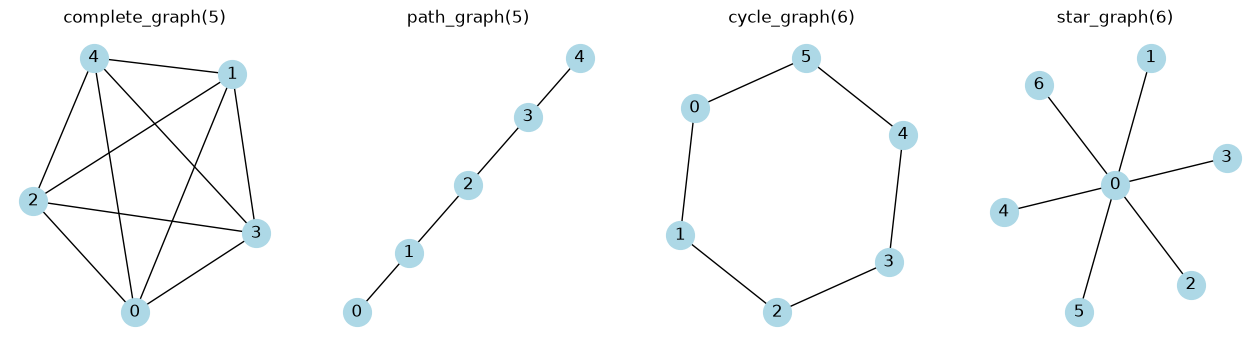

In [16]:
examples = {
    "complete_graph(5)": nx.complete_graph(5),
    "path_graph(5)": nx.path_graph(5),
    "cycle_graph(6)": nx.cycle_graph(6),
    "star_graph(6)": nx.star_graph(6),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (title, graph) in zip(axes, examples.items()):
    nx.draw(graph, ax=ax, with_labels=True, node_color="lightblue", node_size=400)
    ax.set_title(title)
plt.show()

### 4.3 Graph operations

New graphs can also be made by combining or transforming existing ones:

| Operation | What it does |
|---|---|
| `G.subgraph(nodes)` | keeps only the listed nodes and the edges among them (an *induced subgraph*) |
| `nx.union(G1, G2)` | puts two graphs side by side (node names must not overlap) |
| `nx.disjoint_union(G1, G2)` | like union, but renumbers the nodes so overlap doesn't matter |
| `nx.compose(G1, G2)` | merges two graphs; nodes with the same name become one node |
| `nx.complement(G)` | an edge exists exactly where `G` has **no** edge |
| `nx.cartesian_product(G1, G2)` | a "grid-like" product of two graphs |
| `nx.create_empty_copy(G)` | same nodes, no edges |
| `G.to_directed()` / `G.to_undirected()` | convert between undirected and directed |

A few of them, drawn:

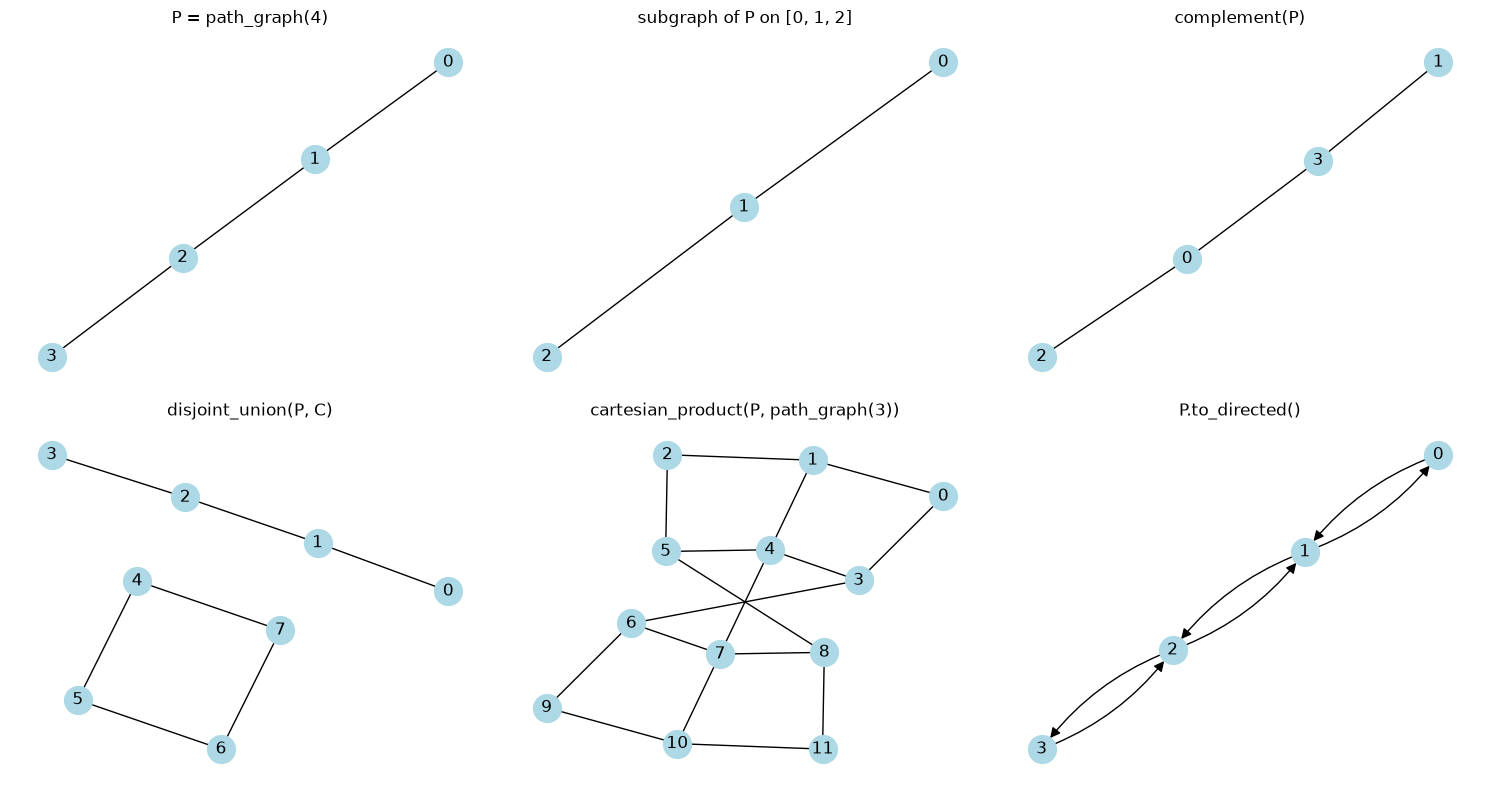

In [17]:
P = nx.path_graph(4)                    # 0-1-2-3
C = nx.cycle_graph(4)                   # a square
ops = {
    "P = path_graph(4)": P,
    "subgraph of P on [0, 1, 2]": P.subgraph([0, 1, 2]),
    "complement(P)": nx.complement(P),
    "disjoint_union(P, C)": nx.disjoint_union(P, C),
    "cartesian_product(P, path_graph(3))": nx.convert_node_labels_to_integers(nx.cartesian_product(P, nx.path_graph(3))),
    "P.to_directed()": P.to_directed(),
}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (title, graph) in zip(axes.flat, ops.items()):
    layout = nx.kamada_kawai_layout(graph) if graph.number_of_edges() else nx.circular_layout(graph)
    extra = {"arrowsize": 15, "connectionstyle": "arc3,rad=0.15"} if graph.is_directed() else {}
    nx.draw(graph, layout, ax=ax, with_labels=True, node_color="lightblue", node_size=400, **extra)
    ax.set_title(title)
plt.tight_layout()
plt.show()

Notice that `P.to_directed()` replaces every undirected edge with **two** arrows, one in each direction.

## 5. Many ways to draw a network

NetworkX's main job is *analysis*, not drawing. It still offers good drawing tools through Matplotlib, and it works with dedicated tools such as Graphviz. To compare options fairly, we'll use one small example throughout: a **study group friendship network**.

The story: Ana, Ben, and Cai live in the same dorm and are all friends. Dee, Eva, Fin, and Gus are in the same club. Cai and Dee are lab partners, and theirs is the *only* friendship linking the two groups.

In [18]:
friends = nx.Graph()
friends.add_edges_from([
    ("Ana", "Ben"), ("Ana", "Cai"), ("Ben", "Cai"),     # the dorm group
    ("Cai", "Dee"),                                      # the lab partners: the only link between the groups
    ("Dee", "Eva"), ("Dee", "Fin"), ("Eva", "Fin"),      # the club group...
    ("Eva", "Gus"), ("Fin", "Gus"),
])
print(friends)

Graph with 7 nodes and 9 edges


### 5.1 Option 1: the one-liner `nx.draw`

Quick and good enough to check your work. Every time you run it the picture may look slightly different, because the default layout involves randomness.

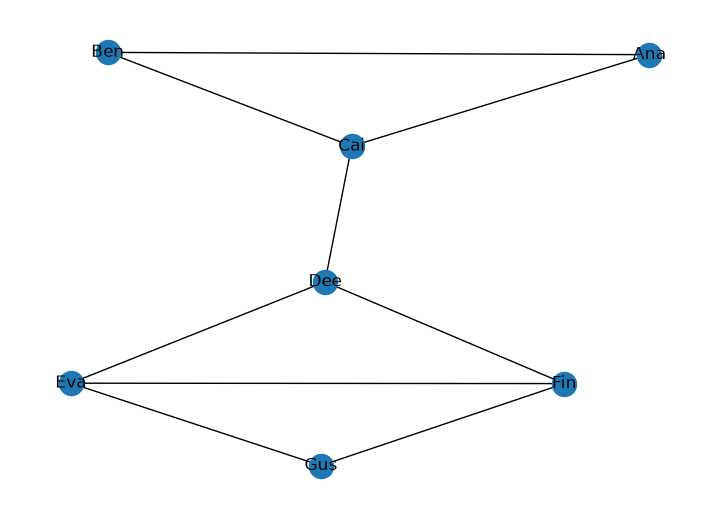

In [19]:
nx.draw(friends, with_labels=True)
plt.show()

### 5.2 Option 2: choosing a layout

A **layout** decides *where* each node goes on the page. The connections are the data; positions are just a choice made for readability. Different layouts suit different purposes:

| Layout | How it places nodes | Good for |
|---|---|---|
| `spring_layout` | edges act like springs pulling connected nodes together; all nodes push each other apart | general purpose; reveals groups |
| `kamada_kawai_layout` | tries to make distances on the page match network distances | small networks, clean pictures |
| `circular_layout` | nodes evenly spaced on a circle | seeing every edge clearly; small networks |
| `shell_layout` | nodes on concentric circles that you choose | showing groups or levels |
| `spectral_layout` | uses mathematics of the network's matrix | revealing clusters in larger graphs |
| `random_layout` | random positions | a baseline (usually messy!) |

A layout function returns a dictionary *node → (x, y) position*, which we pass to the drawing function. `seed=...` fixes the randomness so you get the same picture every time.

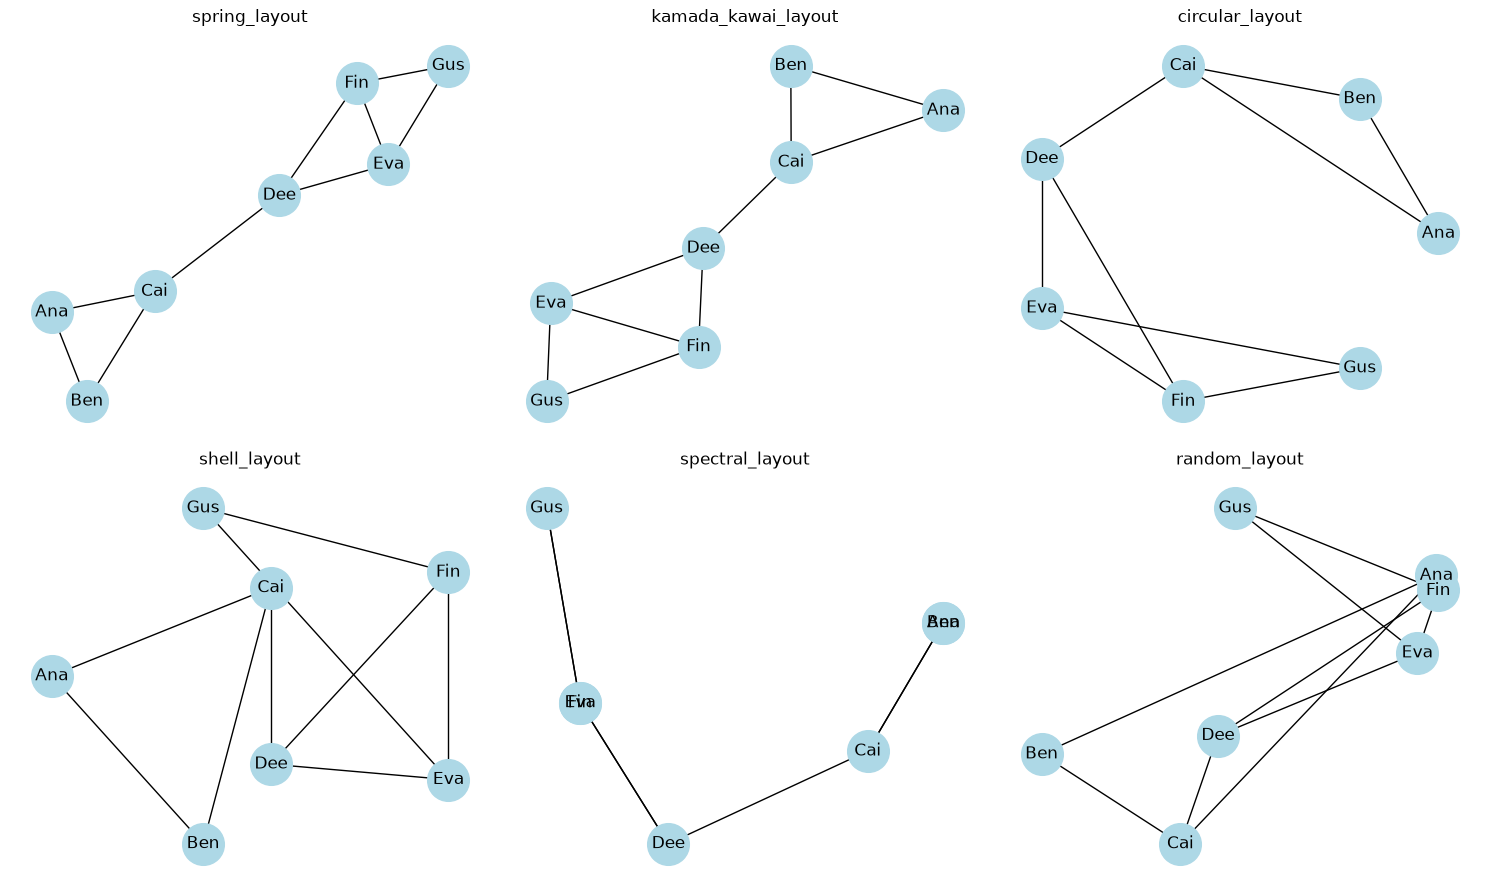

In [20]:
layouts = {
    "spring_layout": nx.spring_layout(friends, seed=1),
    "kamada_kawai_layout": nx.kamada_kawai_layout(friends),
    "circular_layout": nx.circular_layout(friends),
    "shell_layout": nx.shell_layout(friends, nlist=[["Cai", "Dee"], ["Ana", "Ben", "Eva", "Fin", "Gus"]]),
    "spectral_layout": nx.spectral_layout(friends),
    "random_layout": nx.random_layout(friends, seed=1),
}
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (title, pos) in zip(axes.flat, layouts.items()):
    nx.draw(friends, pos, ax=ax, with_labels=True, node_color="lightblue", node_size=900)
    ax.set_title(title)
plt.tight_layout()
plt.show()

It's the same network every time, but some layouts make the "two groups joined by one link" story obvious (spring, Kamada–Kawai), while others hide it (random). Spectral layout even puts some nodes on top of each other (Ana and Ben, Eva and Fin), because they have exactly the same connections within their group. **Always remember that the picture is a choice, not the data.**

### 5.3 Option 3: full control over the appearance

Instead of `nx.draw`, you can draw the pieces separately and style each:

* `nx.draw_networkx_nodes(...)`: the circles (`node_color`, `node_size`, `node_shape`, …);
* `nx.draw_networkx_edges(...)`: the lines (`width`, `edge_color`, `style`, …);
* `nx.draw_networkx_labels(...)`: the text.

Here we colour nodes by group, make the bridge edge thick, red, and dashed, and add a title and legend.

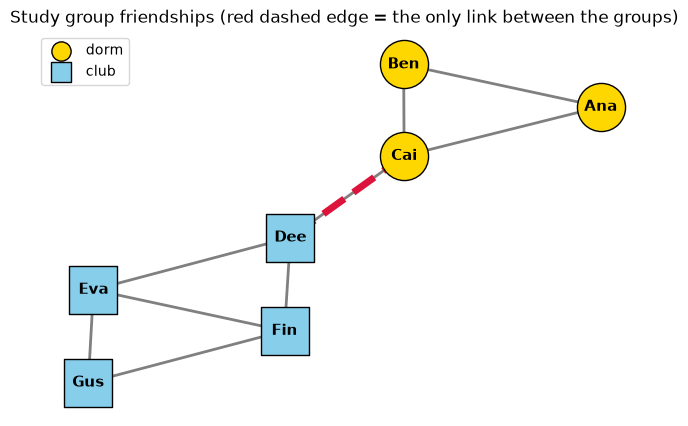

In [21]:
pos = nx.kamada_kawai_layout(friends)       # we'll reuse these positions for the rest of the notebook

dorm = ["Ana", "Ben", "Cai"]
club = ["Dee", "Eva", "Fin", "Gus"]

fig, ax = plt.subplots(figsize=(8, 5))
nx.draw_networkx_nodes(friends, pos, nodelist=dorm, node_color="gold", node_size=1200, edgecolors="black", label="dorm")
nx.draw_networkx_nodes(friends, pos, nodelist=club, node_color="skyblue", node_size=1200, edgecolors="black", node_shape="s", label="club")
nx.draw_networkx_edges(friends, pos, width=2, edge_color="grey")
nx.draw_networkx_edges(friends, pos, edgelist=[("Cai", "Dee")], width=5, edge_color="crimson", style="dashed")
nx.draw_networkx_labels(friends, pos, font_size=11, font_weight="bold")
ax.set_title("Study group friendships (red dashed edge = the only link between the groups)")
ax.legend(scatterpoints=1, markerscale=0.4, loc="upper left")
ax.axis("off")
plt.show()

### 5.4 Option 4: node size and colour that carry information

A very common trick is to let a node's **size or colour represent a number**, such as how many friends it has. Below, `friends.degree(n)` (explained in detail in Section 7) gives the number of friends of `n`. Bigger and darker means more friends.

The second panel recreates the "star" example from the original version of this notebook: node colour and size grow with the node's number.

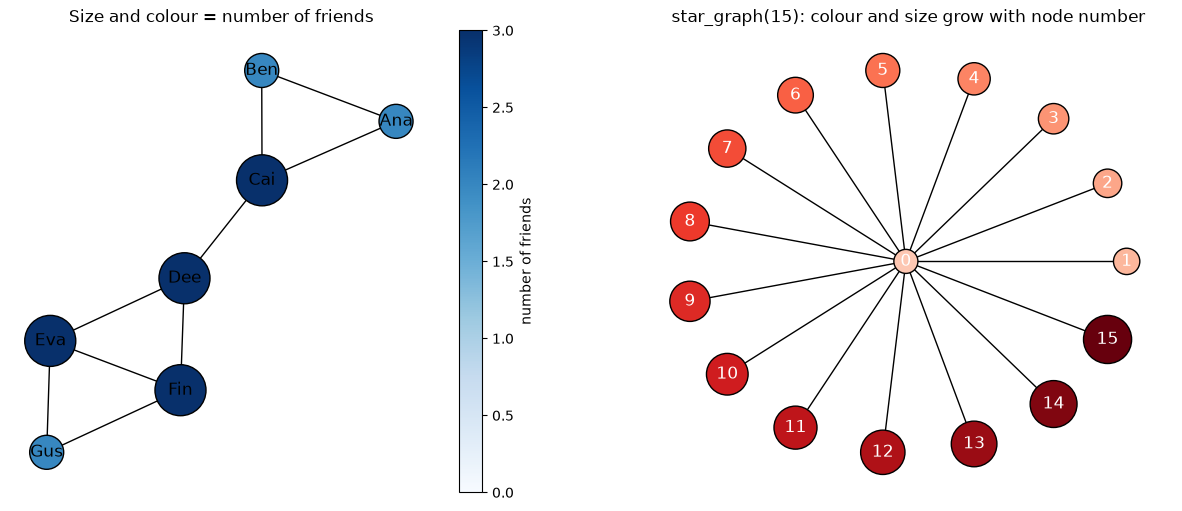

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left: size and colour by number of friends
num_friends = [friends.degree(n) for n in friends.nodes()]
nodes = nx.draw_networkx_nodes(friends, pos, ax=axes[0], node_size=[150 * k ** 2 for k in num_friends],
                               node_color=num_friends, cmap="Blues", vmin=0, vmax=max(num_friends), edgecolors="black")
nx.draw_networkx_edges(friends, pos, ax=axes[0])
nx.draw_networkx_labels(friends, pos, ax=axes[0])
plt.colorbar(nodes, ax=axes[0], label="number of friends")
axes[0].set_title("Size and colour = number of friends"); axes[0].axis("off")

# Right: the 'star' from the original notebook, drawn with matplotlib
star = nx.star_graph(15)                       # node 0 in the middle, nodes 1..15 around it
star_pos = nx.circular_layout(range(1, 16))
star_pos[0] = (0, 0)
nx.draw(star, star_pos, ax=axes[1], with_labels=True, font_color="white",
        node_color=[i for i in star.nodes()], cmap="Reds", vmin=-4, vmax=15,
        node_size=[300 + 60 * i for i in star.nodes()], edgecolors="black")
axes[1].set_title("star_graph(15): colour and size grow with node number")
plt.show()

### 5.5 Option 5: the adjacency matrix

A network can also be drawn as a **table** instead of dots and lines. The **adjacency matrix** has one row and one column per node, with a 1 wherever two nodes are connected and 0 otherwise. For large networks this is often *clearer* than a node-link drawing, which can turn into a "hairball".

For an undirected network the matrix is **symmetric** (a mirror image across the diagonal), because an edge Ana–Ben is also an edge Ben–Ana.

,Ana,Ben,Cai,Dee,Eva,Fin,Gus
Ana,0,1,1,0,0,0,0
Ben,1,0,1,0,0,0,0
Cai,1,1,0,1,0,0,0
Dee,0,0,1,0,1,1,0
Eva,0,0,0,1,0,1,1
Fin,0,0,0,1,1,0,1
Gus,0,0,0,0,1,1,0


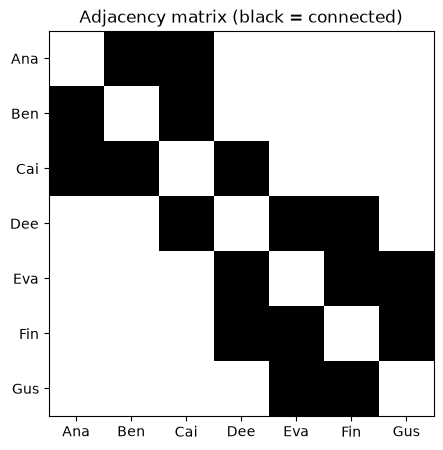

In [23]:
order = ["Ana", "Ben", "Cai", "Dee", "Eva", "Fin", "Gus"]
A = nx.to_pandas_adjacency(friends, nodelist=order, dtype=int)
display(A)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(A.values, cmap="Greys")
ax.set_xticks(range(len(order)), order)
ax.set_yticks(range(len(order)), order)
ax.set_title("Adjacency matrix (black = connected)")
plt.show()

### 5.6 Option 6: Graphviz

[Graphviz](https://graphviz.org/) is a dedicated drawing program that produces very clean diagrams, especially for directed networks and hierarchies. The original version of this notebook used `pygraphviz`, which is often hard to install. The simpler `graphviz` Python package works too.

**Installation (one time):** run `conda install python-graphviz` in Anaconda, *or* install Graphviz itself from [graphviz.org/download](https://graphviz.org/download/) and then run `pip install graphviz`. If it isn't installed, the cell below just prints a message and you can skip it.

The `engine` setting chooses a Graphviz layout: `"neato"` (spring-like), `"circo"` (circular), `"dot"` (top-down hierarchy, for directed graphs).

In [24]:
try:
    import graphviz

    g = graphviz.Graph(engine="neato")          # Graph = undirected; use graphviz.Digraph() for directed
    g.attr("node", shape="circle", style="filled", fontname="Helvetica", fixedsize="true", width="0.7")
    for n in friends.nodes():
        g.node(n, fillcolor="gold" if n in dorm else "skyblue")
    for u, v in friends.edges():
        g.edge(u, v, color="crimson" if {u, v} == {"Cai", "Dee"} else "grey40",
               penwidth="3" if {u, v} == {"Cai", "Dee"} else "1.2")
    display(g)                                  # in Jupyter this shows the picture
    # g.render("friends", format="png")          # uncomment to save a PNG file
except ImportError:
    print("The graphviz package is not installed; skip this cell or see the installation note above.")
except Exception as err:   # e.g. the Graphviz program itself is missing
    print("Graphviz could not draw the picture:", err)

The graphviz package is not installed; skip this cell or see the installation note above.


*Alternative with pygraphviz:* if you have `pygraphviz` installed, `A = nx.nx_agraph.to_agraph(friends); A.draw("friends.png", prog="neato")` converts a NetworkX graph straight into a Graphviz drawing.

### 5.7 Option 7: an interactive picture you can drag around (optional)

The **pyvis** library makes interactive web-page drawings: you can drag nodes, zoom, and hover over them. Install it with `pip install pyvis`, then run the cell below. It creates a file `friends_interactive.html` and displays it in the notebook. (This cell was not run in the saved version of the notebook, so it has no output yet.)

## 6. Directed networks: in-degree and out-degree

### 6.1 A "who follows whom" network

Now let's build a **directed** network with `nx.DiGraph()` ("Di" stands for directed). An edge `("Leo", "Maya")` means **Leo follows Maya**. The arrow points *from* the follower *to* the person being followed.

The story: Maya is a popular account that many people follow. Raj is new and follows everybody, but nobody follows him back yet.

DiGraph with 6 nodes and 13 edges


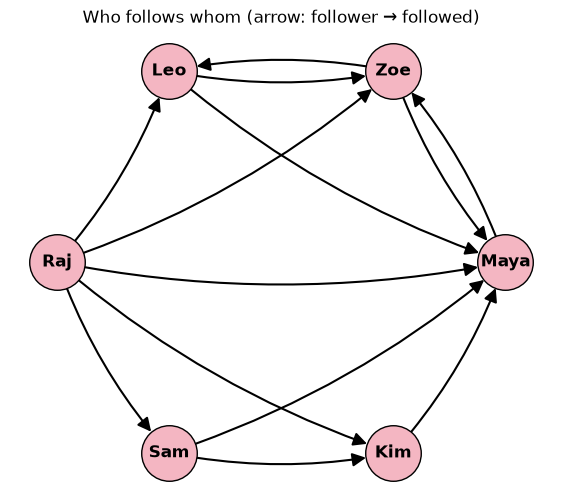

In [27]:
follows = nx.DiGraph()
follows.add_edges_from([
    ("Leo", "Maya"), ("Zoe", "Maya"), ("Sam", "Maya"), ("Kim", "Maya"), ("Raj", "Maya"),
    ("Maya", "Zoe"),                              # Maya follows only one person back
    ("Raj", "Leo"), ("Raj", "Zoe"), ("Raj", "Sam"), ("Raj", "Kim"),   # Raj follows everyone
    ("Leo", "Zoe"), ("Zoe", "Leo"),               # Leo and Zoe follow each other
    ("Sam", "Kim"),
])
print(follows)

pos_f = nx.circular_layout(["Maya", "Zoe", "Leo", "Raj", "Sam", "Kim"])
fig, ax = plt.subplots(figsize=(7, 6))
nx.draw_networkx_nodes(follows, pos_f, node_color="#f4b6c2", node_size=1600, edgecolors="black")
nx.draw_networkx_labels(follows, pos_f, font_weight="bold")
nx.draw_networkx_edges(follows, pos_f, node_size=1600, arrowstyle="-|>", arrowsize=20, width=1.5,
                       connectionstyle="arc3,rad=0.1")     # slight curve so mutual follows don't overlap
ax.set_title("Who follows whom (arrow: follower → followed)")
ax.axis("off")
plt.show()

### 6.2 What in-degree and out-degree mean

In a directed network, each node has two kinds of edges:

* **In-degree** = the number of arrows pointing **into** the node. Here: *how many followers do you have?* It measures **popularity**, **prestige**, or **how much attention you receive**.
* **Out-degree** = the number of arrows pointing **out of** the node. Here: *how many accounts do you follow?* It measures **activity**, **sociability**, or **how much attention you give**.

High in-degree and high out-degree describe very different roles. A celebrity has a huge in-degree and a small out-degree. A spam account may have a huge out-degree and a tiny in-degree.

### 6.3 Calculating them by hand

Look at the picture and count arrows:

* **Maya**: arrows *in* from Leo, Zoe, Sam, Kim, Raj → in-degree **5**. One arrow *out* (to Zoe) → out-degree **1**.
* **Raj**: no arrows in → in-degree **0**. Arrows out to Maya, Leo, Zoe, Sam, Kim → out-degree **5**.
* **Zoe**: in from Maya, Raj, Leo → **3**; out to Maya, Leo → **2**.

A useful check: every arrow leaves one node and enters another, so **the in-degrees and the out-degrees each add up to the total number of edges** (13 here).

### 6.4 Calculating them with the adjacency matrix

In a directed adjacency matrix, the entry in row *i* and column *j* is 1 if *i → j* (row *i* follows column *j*). Then:

* **out-degree of a node = the sum of its row** (everyone it points to);
* **in-degree of a node = the sum of its column** (everyone pointing to it).

Unlike the undirected case, this matrix is generally **not** symmetric.

In [28]:
people = ["Maya", "Zoe", "Leo", "Raj", "Sam", "Kim"]
M = nx.to_pandas_adjacency(follows, nodelist=people, dtype=int)
M["OUT-DEGREE (row sum)"] = M[people].sum(axis=1)
M.loc["IN-DEGREE (column sum)"] = M.sum(axis=0)
M.index.name = "row follows column →"
M

,Maya,Zoe,Leo,Raj,Sam,Kim,OUT-DEGREE (row sum)
row follows column →,,,,,,,
Maya,0,1,0,0,0,0,1
Zoe,1,0,1,0,0,0,2
Leo,1,1,0,0,0,0,2
Raj,1,1,1,0,1,1,5
Sam,1,0,0,0,0,1,2
Kim,1,0,0,0,0,0,1
IN-DEGREE (column sum),5,3,2,0,1,2,13


### 6.5 Calculating them with NetworkX

* `follows.in_degree(n)` and `follows.out_degree(n)` give the values for one node.
* `follows.in_degree()` (no argument) gives them for every node.

We also do it "the long way", by looping over all edges and counting, to show there's no magic. Both give the same answer.

In [29]:
# The NetworkX way
print("Maya: in-degree =", follows.in_degree("Maya"), ", out-degree =", follows.out_degree("Maya"))

# The long way: go through every edge (u -> v) and add 1 to u's out-count and v's in-count
in_count = {n: 0 for n in follows.nodes()}
out_count = {n: 0 for n in follows.nodes()}
for u, v in follows.edges():
    out_count[u] += 1
    in_count[v] += 1

table = pd.DataFrame({
    "in-degree (followers)": dict(follows.in_degree()),
    "out-degree (following)": dict(follows.out_degree()),
    "in (counted by hand)": in_count,
    "out (counted by hand)": out_count,
})
display(table.sort_values("in-degree (followers)", ascending=False))
print("Sum of in-degrees =", sum(in_count.values()), "| sum of out-degrees =", sum(out_count.values()),
      "| number of edges =", follows.number_of_edges())

Maya: in-degree = 5 , out-degree = 1


,in-degree (followers),out-degree (following),in (counted by hand),out (counted by hand)
Maya,5,1,5,1
Zoe,3,2,3,2
Leo,2,2,2,2
Kim,2,1,2,1
Sam,1,2,1,2
Raj,0,5,0,5


Sum of in-degrees = 13 | sum of out-degrees = 13 | number of edges = 13


### 6.6 Visualizing in- and out-degree

A **scatter plot** of in-degree against out-degree is a nice way to see roles at a glance. Nodes in the top-left are *popular but selective*; nodes in the bottom-right are *active followers who aren't followed back*.

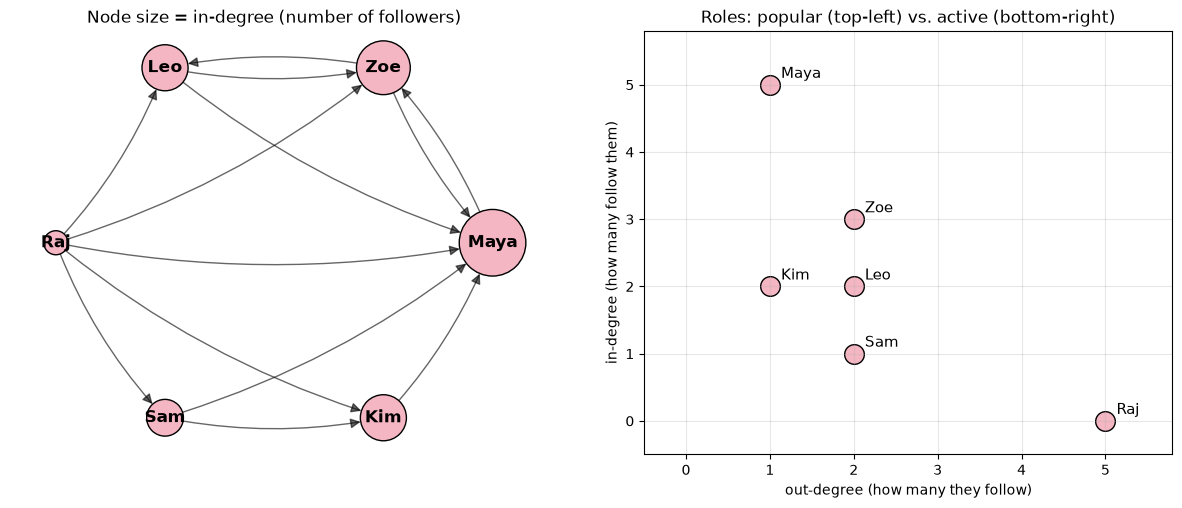

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

indeg = dict(follows.in_degree())
outdeg = dict(follows.out_degree())

# Left: network with node size = in-degree (popularity)
nx.draw_networkx_nodes(follows, pos_f, ax=axes[0], node_size=[300 + 400 * indeg[n] for n in follows],
                       node_color="#f4b6c2", edgecolors="black")
nx.draw_networkx_labels(follows, pos_f, ax=axes[0], font_weight="bold")
nx.draw_networkx_edges(follows, pos_f, ax=axes[0], node_size=[300 + 400 * indeg[n] for n in follows],
                       arrowsize=15, connectionstyle="arc3,rad=0.1", alpha=0.6)
axes[0].set_title("Node size = in-degree (number of followers)"); axes[0].axis("off")

# Right: in-degree vs out-degree
for n in follows:
    axes[1].scatter(outdeg[n], indeg[n], s=200, color="#f4b6c2", edgecolors="black")
    axes[1].annotate(n, (outdeg[n], indeg[n]), xytext=(8, 5), textcoords="offset points", fontsize=11)
axes[1].set_xlabel("out-degree (how many they follow)")
axes[1].set_ylabel("in-degree (how many follow them)")
axes[1].set_xlim(-0.5, 5.8); axes[1].set_ylim(-0.5, 5.8)
axes[1].set_title("Roles: popular (top-left) vs. active (bottom-right)")
axes[1].grid(alpha=0.3)
plt.show()

**What does an undirected network have?** Just **degree**: the number of edges touching the node. There are no arrows, so "in" and "out" don't exist. In NetworkX, `G.degree(n)` works for both kinds of network; for a directed network it returns *in-degree + out-degree*.

## 7. Degree centrality

### 7.1 The idea

**Centrality** is a family of measures that try to answer *"how important is this node?"* Each one defines "important" differently. **Degree centrality** is the simplest: **a node is important if it has many direct connections.**

* **Question it answers:** *Who has the most direct contacts? Who is most active, most popular, or most exposed?*
* **Real-world reading:** the person who knows the most people; the airport with the most direct flights.

### 7.2 How to calculate it

The raw degree depends on network size: having 5 friends means a lot in a group of 7, and little in a school of 2,000. So we **normalize** it, dividing by the largest possible degree, which is $n - 1$ ($n$ = number of nodes; you can be connected to everyone except yourself):

$$\text{degree centrality}(v) = \frac{\text{degree}(v)}{n - 1}$$

The result is between 0 (no connections) and 1 (connected to everybody). It can be read as *the share of everyone else that this node is directly connected to*.

**By hand, for the study group** ($n = 7$, so we divide by 6):

| Person | Friends | Degree | Degree centrality |
|---|---|---|---|
| Ana | Ben, Cai | 2 | 2/6 = 0.333 |
| Ben | Ana, Cai | 2 | 2/6 = 0.333 |
| Cai | Ana, Ben, Dee | 3 | 3/6 = 0.500 |
| Dee | Cai, Eva, Fin | 3 | 3/6 = 0.500 |
| Eva | Dee, Fin, Gus | 3 | 3/6 = 0.500 |
| Fin | Dee, Eva, Gus | 3 | 3/6 = 0.500 |
| Gus | Eva, Fin | 2 | 2/6 = 0.333 |

Now let Python check our work:

In [31]:
n = friends.number_of_nodes()

# The long way: degree divided by (n - 1)
by_hand = {person: friends.degree(person) / (n - 1) for person in friends.nodes()}

# The NetworkX way
with_nx = nx.degree_centrality(friends)

pd.DataFrame({"degree": dict(friends.degree()),
              "degree / (n-1)  (by hand)": by_hand,
              "nx.degree_centrality": with_nx}).round(3)

,degree,degree / (n-1) (by hand),nx.degree_centrality
Ana,2,0.333,0.333
Ben,2,0.333,0.333
Cai,3,0.500,0.500
Dee,3,0.500,0.500
Eva,3,0.500,0.500
Fin,3,0.500,0.500
Gus,2,0.333,0.333


### 7.3 Degree centrality in a directed network

In a directed network there are two versions:

$$\text{in-degree centrality}(v) = \frac{\text{in-degree}(v)}{n-1} \qquad \text{out-degree centrality}(v) = \frac{\text{out-degree}(v)}{n-1}$$

For the "follows" network, $n = 6$, so we divide by 5. Maya's in-degree centrality is $5/5 = 1$: **everyone else follows her**. Raj's out-degree centrality is also $5/5 = 1$: **he follows everyone else**.

(Watch out: `nx.degree_centrality` on a directed graph uses *in + out* and can therefore be larger than 1.)

In [32]:
pd.DataFrame({
    "in-degree centrality": nx.in_degree_centrality(follows),
    "out-degree centrality": nx.out_degree_centrality(follows),
    "degree centrality (in+out)": nx.degree_centrality(follows),
}).round(2).sort_values("in-degree centrality", ascending=False)

,in-degree centrality,out-degree centrality,degree centrality (in+out)
Maya,1.0,0.2,1.2
Zoe,0.6,0.4,1.0
Leo,0.4,0.4,0.8
Kim,0.4,0.2,0.6
Sam,0.2,0.4,0.6
Raj,0.0,1.0,1.0


### 7.4 What degree centrality does and doesn't tell you

* ✅ It's easy to compute and explain, and it's often a good first guess at "who matters".
* ❌ It only looks at **direct** connections. It ignores *who* you are connected to and *where* you sit in the overall network.

Look again at the study group: Cai, Dee, Eva, and Fin all have **exactly the same** degree (3). Yet Cai and Dee hold the two groups together, while Eva and Fin don't. Degree can't see this difference. The next two measures can, and both are built on the idea of **paths**.

## 8. Paths and distances

A **path** is a route through the network, following edges from node to node. The **length** of a path is the number of edges (steps) it uses. The **shortest path** between two nodes is the route with the fewest steps, and its length is the **distance** between them.

For example, from Ana to Gus: Ana → Cai → Dee → Eva → Gus is 4 steps. There is no shorter route, so the distance from Ana to Gus is 4. But Ana → Cai → Dee → **Fin** → Gus is *also* 4 steps. **There can be more than one shortest path**, and this matters for betweenness.

NetworkX tools:

* `nx.shortest_path(G, a, b)`: one shortest path;
* `nx.all_shortest_paths(G, a, b)`: all of them;
* `nx.shortest_path_length(G, a, b)`: the distance.

One shortest path Ana → Gus:  ['Ana', 'Cai', 'Dee', 'Eva', 'Gus']
All shortest paths Ana → Gus: [['Ana', 'Cai', 'Dee', 'Eva', 'Gus'], ['Ana', 'Cai', 'Dee', 'Fin', 'Gus']]
Distance Ana → Gus:           4


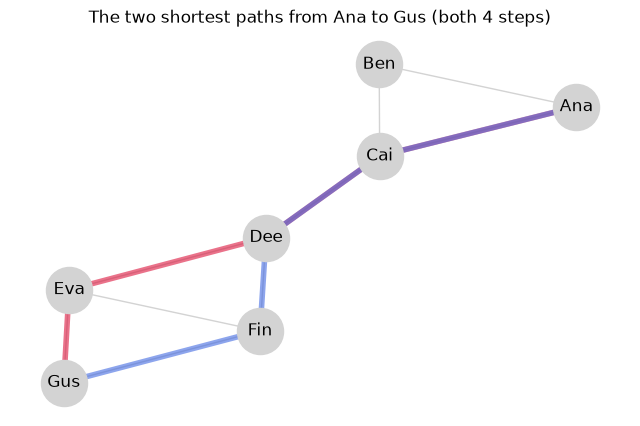

In [33]:
print("One shortest path Ana → Gus: ", nx.shortest_path(friends, "Ana", "Gus"))
print("All shortest paths Ana → Gus:", list(nx.all_shortest_paths(friends, "Ana", "Gus")))
print("Distance Ana → Gus:          ", nx.shortest_path_length(friends, "Ana", "Gus"))

fig, ax = plt.subplots(figsize=(8, 5))
nx.draw(friends, pos, ax=ax, with_labels=True, node_color="lightgrey", node_size=1100, edge_color="lightgrey")
for path, colour in zip(nx.all_shortest_paths(friends, "Ana", "Gus"), ["crimson", "royalblue"]):
    nx.draw_networkx_edges(friends, pos, ax=ax, edgelist=list(zip(path, path[1:])), width=4, edge_color=colour, alpha=0.6)
ax.set_title("The two shortest paths from Ana to Gus (both 4 steps)")
plt.show()

The **distance table** lists the distance between every pair of people. We'll use it to calculate closeness centrality in Section 10.

In [34]:
dist = pd.DataFrame(dict(nx.shortest_path_length(friends))).loc[order, order]
dist

,Ana,Ben,Cai,Dee,Eva,Fin,Gus
Ana,0,1,1,2,3,3,4
Ben,1,0,1,2,3,3,4
Cai,1,1,0,1,2,2,3
Dee,2,2,1,0,1,1,2
Eva,3,3,2,1,0,1,1
Fin,3,3,2,1,1,0,1
Gus,4,4,3,2,1,1,0


## 9. Betweenness centrality

### 9.1 The idea

**Betweenness centrality** says **a node is important if it lies on the shortest paths between other nodes**. Picture information, gossip, or goods travelling through the network along the quickest routes. A node with high betweenness is a **bridge**, **broker**, or **gatekeeper**: many routes pass through it, so it can speed things up, slow them down, filter them, or control them.

* **Question it answers:** *Who sits "in between" others? Who connects groups that would otherwise be separated? Whose removal would most disrupt communication?*
* **Real-world reading:** the colleague who links two departments; a hub airport where you must change planes.

### 9.2 How to calculate it

For a node $v$, look at **every pair** of *other* nodes $(s, t)$ and ask: *what fraction of the shortest paths from $s$ to $t$ pass through $v$?* Then add up these fractions:

$$\text{betweenness}(v) = \sum_{\text{pairs } s,t \text{ (not } v)} \frac{\text{number of shortest } s\text{–}t \text{ paths that go through } v}{\text{number of shortest } s\text{–}t \text{ paths}}$$

Step by step:

1. List every pair of nodes, not including $v$.
2. For each pair, find all the shortest paths between them.
3. Count how many of those paths pass **through** $v$ (as a stopover, not as a start or end point).
4. Divide by the total number of shortest paths for that pair. This gives 1 if *all* shortest paths go through $v$, ½ if half of them do, and so on.
5. Add up the numbers for all pairs.

**Normalizing.** As with degree, we usually divide by the largest possible value, so results are between 0 and 1. In an undirected network with $n$ nodes, the number of pairs not involving $v$ is $\frac{(n-1)(n-2)}{2}$. For our 7 friends that's $\frac{6 \times 5}{2} = 15$.

### 9.3 By hand, for the study group

**Dee.** Every route from the dorm side {Ana, Ben, Cai} to the club side {Eva, Fin, Gus} must pass through Dee. That's 3 × 3 = **9 pairs**, each contributing 1. No other pair needs Dee. Betweenness(Dee) = **9**, normalized 9/15 = **0.60**.

**Cai.** Every route from {Ana, Ben} to {Dee, Eva, Fin, Gus} passes through Cai: 2 × 4 = **8 pairs**. Betweenness(Cai) = **8**, normalized 8/15 = **0.53**.

**Eva.** Eva is only needed to reach Gus from Dee's side. From Dee to Gus there are **two** shortest paths, Dee → Eva → Gus and Dee → Fin → Gus, and only one goes through Eva, so this pair contributes **½**. The same is true for Cai–Gus, Ana–Gus, and Ben–Gus. Betweenness(Eva) = 4 × ½ = **2**, normalized 2/15 = **0.13**. **Fin** is the mirror image of Eva: also **2**.

**Ana, Ben, Gus.** No shortest path ever passes *through* them, so betweenness = **0**. They are on the edge of the network.

The code below does exactly the same calculation, writing out every pair, so you can check each step.

In [35]:
def betweenness_worksheet(G, v):
    # Show, pair by pair, how much each pair (s, t) contributes to the betweenness of v
    rows = []
    others = [x for x in G.nodes() if x != v]
    for i, s in enumerate(others):
        for t in others[i + 1:]:                      # each pair once (undirected)
            paths = list(nx.all_shortest_paths(G, s, t))
            through_v = [p for p in paths if v in p[1:-1]]   # v must be a stop in the middle
            if through_v:                             # only show pairs that contribute something
                rows.append({"pair": f"{s} – {t}",
                             "shortest paths": "  |  ".join(" → ".join(p) for p in paths),
                             "# through " + v: len(through_v),
                             "# shortest": len(paths),
                             "contribution": len(through_v) / len(paths)})
    return pd.DataFrame(rows)

ws = betweenness_worksheet(friends, "Eva")
display(ws)
print("Betweenness of Eva = sum of contributions =", ws["contribution"].sum())

,pair,shortest paths,# through Eva,# shortest,contribution
0,Ana – Gus,Ana → Cai → Dee → Eva → Gus | Ana → Cai → De...,1,2,0.5
1,Ben – Gus,Ben → Cai → Dee → Eva → Gus | Ben → Cai → De...,1,2,0.5
2,Cai – Gus,Cai → Dee → Eva → Gus | Cai → Dee → Fin → Gus,1,2,0.5
3,Dee – Gus,Dee → Eva → Gus | Dee → Fin → Gus,1,2,0.5


Betweenness of Eva = sum of contributions = 2.0


In [36]:
ws_dee = betweenness_worksheet(friends, "Dee")
display(ws_dee)
print("Betweenness of Dee =", ws_dee["contribution"].sum())

,pair,shortest paths,# through Dee,# shortest,contribution
0,Ana – Eva,Ana → Cai → Dee → Eva,1,1,1.0
1,Ana – Fin,Ana → Cai → Dee → Fin,1,1,1.0
2,Ana – Gus,Ana → Cai → Dee → Eva → Gus | Ana → Cai → De...,2,2,1.0
3,Ben – Eva,Ben → Cai → Dee → Eva,1,1,1.0
4,Ben – Fin,Ben → Cai → Dee → Fin,1,1,1.0
5,Ben – Gus,Ben → Cai → Dee → Eva → Gus | Ben → Cai → De...,2,2,1.0
6,Cai – Eva,Cai → Dee → Eva,1,1,1.0
7,Cai – Fin,Cai → Dee → Fin,1,1,1.0
8,Cai – Gus,Cai → Dee → Eva → Gus | Cai → Dee → Fin → Gus,2,2,1.0


Betweenness of Dee = 9.0


### 9.4 With NetworkX

`nx.betweenness_centrality(G)` does all of this for every node at once. By default it returns the **normalized** values; `normalized=False` gives the raw sums that we calculated by hand.

In [37]:
pd.DataFrame({
    "degree": dict(friends.degree()),
    "betweenness (raw)": nx.betweenness_centrality(friends, normalized=False),
    "betweenness (normalized)": nx.betweenness_centrality(friends),
}).round(3).sort_values("betweenness (raw)", ascending=False)

,degree,betweenness (raw),betweenness (normalized)
Dee,3,9.0,0.600
Cai,3,8.0,0.533
Eva,3,2.0,0.133
Fin,3,2.0,0.133
Ana,2,0.0,0.000
Ben,2,0.0,0.000
Gus,2,0.0,0.000


### 9.5 Visualizing betweenness

On the left, node size and colour show betweenness. On the right, we draw **every** shortest path that passes through Dee; there are a lot of them!

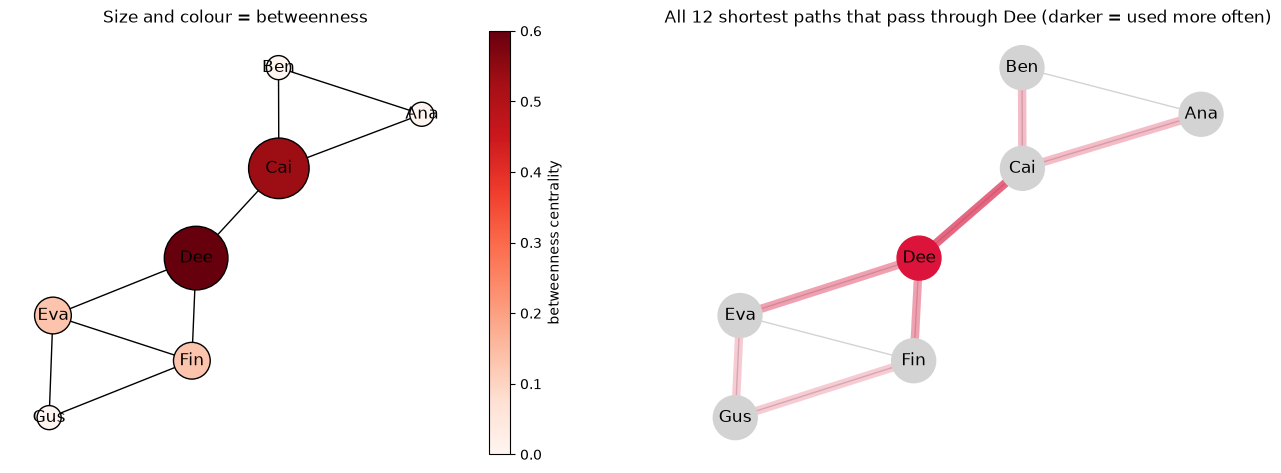

In [38]:
btw = nx.betweenness_centrality(friends)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
nodes = nx.draw_networkx_nodes(friends, pos, ax=axes[0], node_size=[300 + 3000 * btw[n] for n in friends],
                               node_color=[btw[n] for n in friends], cmap="Reds", edgecolors="black")
nx.draw_networkx_edges(friends, pos, ax=axes[0])
nx.draw_networkx_labels(friends, pos, ax=axes[0])
plt.colorbar(nodes, ax=axes[0], label="betweenness centrality")
axes[0].set_title("Size and colour = betweenness"); axes[0].axis("off")

nx.draw(friends, pos, ax=axes[1], with_labels=True, node_color=["crimson" if n == "Dee" else "lightgrey" for n in friends],
        node_size=1000, edge_color="lightgrey")
count = 0
for s in friends:
    for t in friends:
        if s < t and "Dee" not in (s, t):
            for p in nx.all_shortest_paths(friends, s, t):
                if "Dee" in p:
                    count += 1
                    nx.draw_networkx_edges(friends, pos, ax=axes[1], edgelist=list(zip(p, p[1:])),
                                           width=6, edge_color="crimson", alpha=0.08)
axes[1].set_title(f"All {count} shortest paths that pass through Dee (darker = used more often)")
plt.show()

### 9.6 What betweenness tells you

* **Same degree, very different betweenness.** Cai, Dee, Eva, and Fin all have 3 friends. But Dee (0.60) and Cai (0.53) are the bridges between the groups, while Eva and Fin (0.13) mostly duplicate each other: if one disappears, the other still connects Gus.
* **Vulnerability.** If Cai and Dee stop being lab partners, the network splits into two pieces. High-betweenness nodes and edges are where networks are **fragile**.
* **Power and risk.** Brokers can control what passes between groups, but they also carry the burden of holding the network together.

**Directed networks.** The calculation is the same, except paths must follow the arrows, and the pair (*s*, *t*) is different from (*t*, *s*). In the follows network, the only nodes on directed shortest paths are those who pass messages along:

In [39]:
pd.Series(nx.betweenness_centrality(follows), name="betweenness (directed)").round(3).sort_values(ascending=False).to_frame()

,betweenness (directed)
Maya,0.20
Zoe,0.15
Leo,0.00
Sam,0.00
Kim,0.00
Raj,0.00


For example, Kim → Maya → Zoe is the only shortest route from Kim to Zoe, so Maya relays it. Raj has betweenness 0: nobody can reach *him*, so no path can pass *through* him.

## 10. Closeness centrality

### 10.1 The idea

**Closeness centrality** says **a node is important if it is close to everyone else**, meaning it can reach all other nodes in few steps.

* **Question it answers:** *Who could spread information to the whole network fastest? Who has the quickest access to everyone?*
* **Real-world reading:** the best place to build a fire station; the person to tell if you want news to reach everyone quickly.

Betweenness is about being *in the way*; closeness is about being *nearby*.

### 10.2 How to calculate it

1. Find the distance from the node to **every** other node (one row of the distance table).
2. Add them up. A **small** total means the node is close to everyone.
3. Since we want "bigger = more central", take the **reciprocal** and multiply by $n-1$ so that results are between 0 and 1:

$$\text{closeness}(v) = \frac{n-1}{\text{sum of distances from } v \text{ to all other nodes}}$$

Another way to read this: closeness is **1 divided by the average distance** to everyone else. A node directly connected to everyone has average distance 1, so closeness = 1.

### 10.3 By hand, for the study group

Using the distance table from Section 8 ($n - 1 = 6$):

| Person | Distances to the others | Sum | Average | Closeness = 6 / sum |
|---|---|---|---|---|
| Ana | Ben 1, Cai 1, Dee 2, Eva 3, Fin 3, Gus 4 | 14 | 2.33 | 6/14 = **0.429** |
| Ben | Ana 1, Cai 1, Dee 2, Eva 3, Fin 3, Gus 4 | 14 | 2.33 | 6/14 = **0.429** |
| Cai | Ana 1, Ben 1, Dee 1, Eva 2, Fin 2, Gus 3 | 10 | 1.67 | 6/10 = **0.600** |
| Dee | Cai 1, Eva 1, Fin 1, Ana 2, Ben 2, Gus 2 | 9 | 1.50 | 6/9 = **0.667** |
| Eva | Dee 1, Fin 1, Gus 1, Cai 2, Ana 3, Ben 3 | 11 | 1.83 | 6/11 = **0.545** |
| Fin | Dee 1, Eva 1, Gus 1, Cai 2, Ana 3, Ben 3 | 11 | 1.83 | 6/11 = **0.545** |
| Gus | Eva 1, Fin 1, Dee 2, Cai 3, Ana 4, Ben 4 | 15 | 2.50 | 6/15 = **0.400** |

Dee is the closest to everyone (no one is more than 2 steps away from Dee). Gus is the furthest out.

Let's reproduce the table with code, then compare with NetworkX's `nx.closeness_centrality`:

In [40]:
n = friends.number_of_nodes()
closeness_table = pd.DataFrame({
    "sum of distances": dist.sum(axis=1),
    "average distance": dist.sum(axis=1) / (n - 1),
})
closeness_table["closeness (by hand) = (n-1)/sum"] = (n - 1) / closeness_table["sum of distances"]
closeness_table["nx.closeness_centrality"] = pd.Series(nx.closeness_centrality(friends))
closeness_table.round(3).sort_values("nx.closeness_centrality", ascending=False)

,sum of distances,average distance,closeness (by hand) = (n-1)/sum,nx.closeness_centrality
Dee,9,1.500,0.667,0.667
Cai,10,1.667,0.600,0.600
Eva,11,1.833,0.545,0.545
Fin,11,1.833,0.545,0.545
Ana,14,2.333,0.429,0.429
Ben,14,2.333,0.429,0.429
Gus,15,2.500,0.400,0.400


### 10.4 Visualizing closeness

A nice way to see closeness is to **colour the network by distance from one person**. Below, Dee reaches everyone within 2 steps, while from Gus it takes up to 4.

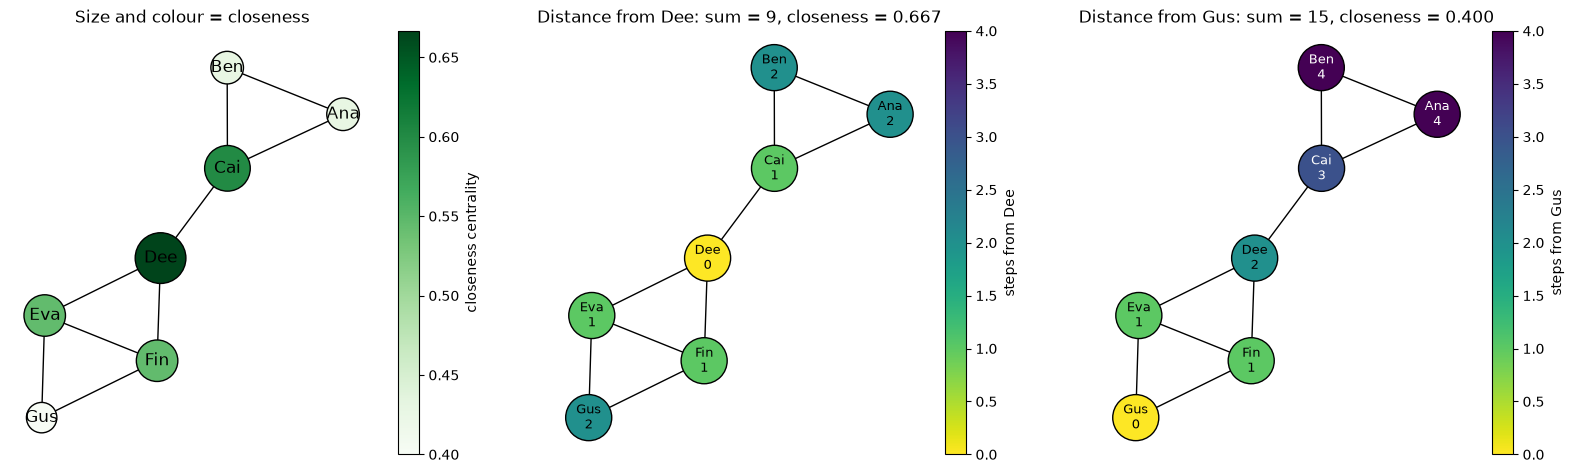

In [41]:
clo = nx.closeness_centrality(friends)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
nodes = nx.draw_networkx_nodes(friends, pos, ax=axes[0], node_size=[3000 * clo[n] ** 2 for n in friends],
                               node_color=[clo[n] for n in friends], cmap="Greens", edgecolors="black")
nx.draw_networkx_edges(friends, pos, ax=axes[0])
nx.draw_networkx_labels(friends, pos, ax=axes[0])
plt.colorbar(nodes, ax=axes[0], label="closeness centrality")
axes[0].set_title("Size and colour = closeness"); axes[0].axis("off")

for ax, person in zip(axes[1:], ["Dee", "Gus"]):
    d = nx.shortest_path_length(friends, person)
    nodes = nx.draw_networkx_nodes(friends, pos, ax=ax, node_color=[d[n] for n in friends], cmap="viridis_r",
                                   vmin=0, vmax=4, node_size=1100, edgecolors="black")
    nx.draw_networkx_edges(friends, pos, ax=ax)
    for n in friends:   # white text on dark nodes, black text on light ones
        nx.draw_networkx_labels(friends, pos, ax=ax, labels={n: f"{n}\n{d[n]}"}, font_size=9,
                                font_color="white" if d[n] >= 3 else "black")
    plt.colorbar(nodes, ax=ax, label=f"steps from {person}")
    ax.set_title(f"Distance from {person}: sum = {sum(d.values())}, closeness = {clo[person]:.3f}")
    ax.axis("off")
plt.show()

### 10.5 What closeness tells you, and two cautions

* Closeness rewards nodes **in the middle** of the network, even if they don't have the most connections.
* Closeness values are often **bunched together** (here everyone is between 0.40 and 0.67), because distances in networks tend to be short. Small differences can still be meaningful.

**Caution 1: disconnected networks.** If some nodes can't be reached at all, the distance is "infinite" and the simple formula breaks. NetworkX handles this by computing closeness within the part of the network that the node can reach, then scaling down by how much of the network that is.

**Caution 2: directed networks.** Distances follow the arrows, so "distance from A to B" may differ from "distance from B to A". **By default, NetworkX's `closeness_centrality` on a directed graph uses *incoming* distances**: how easily others can reach *you*. To measure how easily *you* can reach others, compute it on the reversed graph, `follows.reverse()`.

In [42]:
pd.DataFrame({
    "closeness (incoming: others reach me)": nx.closeness_centrality(follows),
    "closeness (outgoing: I reach others)": nx.closeness_centrality(follows.reverse()),
}).round(3).sort_values("closeness (incoming: others reach me)", ascending=False)

,closeness (incoming: others reach me),closeness (outgoing: I reach others)
Maya,1.000,0.267
Zoe,0.714,0.400
Leo,0.500,0.400
Kim,0.400,0.300
Sam,0.200,0.457
Raj,0.000,1.000


In the follows network, everybody reaches Maya in one step, so her **incoming** closeness is 1. Raj, who follows everyone, has the highest **outgoing** closeness, while his incoming closeness is 0 because no one can reach him at all.

## 11. Putting it all together on a real network

### 11.1 Zachary's karate club

In the 1970s, sociologist Wayne Zachary recorded the friendships among 34 members of a university karate club. During his study, a conflict between the instructor ("Mr. Hi", node 0) and the club's administrator ("Officer", node 33) split the club in two. Each node's `club` attribute records which side the member joined. This network is built into NetworkX and is one of the most famous datasets in network science.

In [43]:
K = nx.karate_club_graph()
print(K)
print("Node 0:", K.nodes[0], "| Node 33:", K.nodes[33])

Graph named "Zachary's Karate Club" with 34 nodes and 78 edges
Node 0: {'club': 'Mr. Hi'} | Node 33: {'club': 'Officer'}


### 11.2 All measures at once

We compute the measures from this tutorial for all 34 members and list the top 6 by each. (This network is undirected, so there's no in- or out-degree.)

In [44]:
kc = pd.DataFrame({
    "club": nx.get_node_attributes(K, "club"),
    "degree": dict(K.degree()),
    "degree centrality": nx.degree_centrality(K),
    "betweenness": nx.betweenness_centrality(K),
    "closeness": nx.closeness_centrality(K),
})
kc.index.name = "member"

for measure in ["degree centrality", "betweenness", "closeness"]:
    print(f"Top 6 by {measure}:", list(kc[measure].sort_values(ascending=False).head(6).index))
kc.sort_values("betweenness", ascending=False).head(8).round(3)

Top 6 by degree centrality: [33, 0, 32, 2, 1, 3]
Top 6 by betweenness: [0, 33, 32, 2, 31, 8]
Top 6 by closeness: [0, 2, 33, 31, 13, 32]


,club,degree,degree centrality,betweenness,closeness
member,,,,,
0,Mr. Hi,16,0.485,0.438,0.569
33,Officer,17,0.515,0.304,0.550
32,Officer,12,0.364,0.145,0.516
2,Mr. Hi,10,0.303,0.144,0.559
31,Officer,6,0.182,0.138,0.541
8,Mr. Hi,5,0.152,0.056,0.516
1,Mr. Hi,9,0.273,0.054,0.485
13,Mr. Hi,5,0.152,0.046,0.516


### 11.3 Side-by-side visualization

The same network is drawn three times, with node size and colour set by each measure. Square nodes joined Mr. Hi's group and circles joined the Officer's. Compare which nodes stand out in each panel.

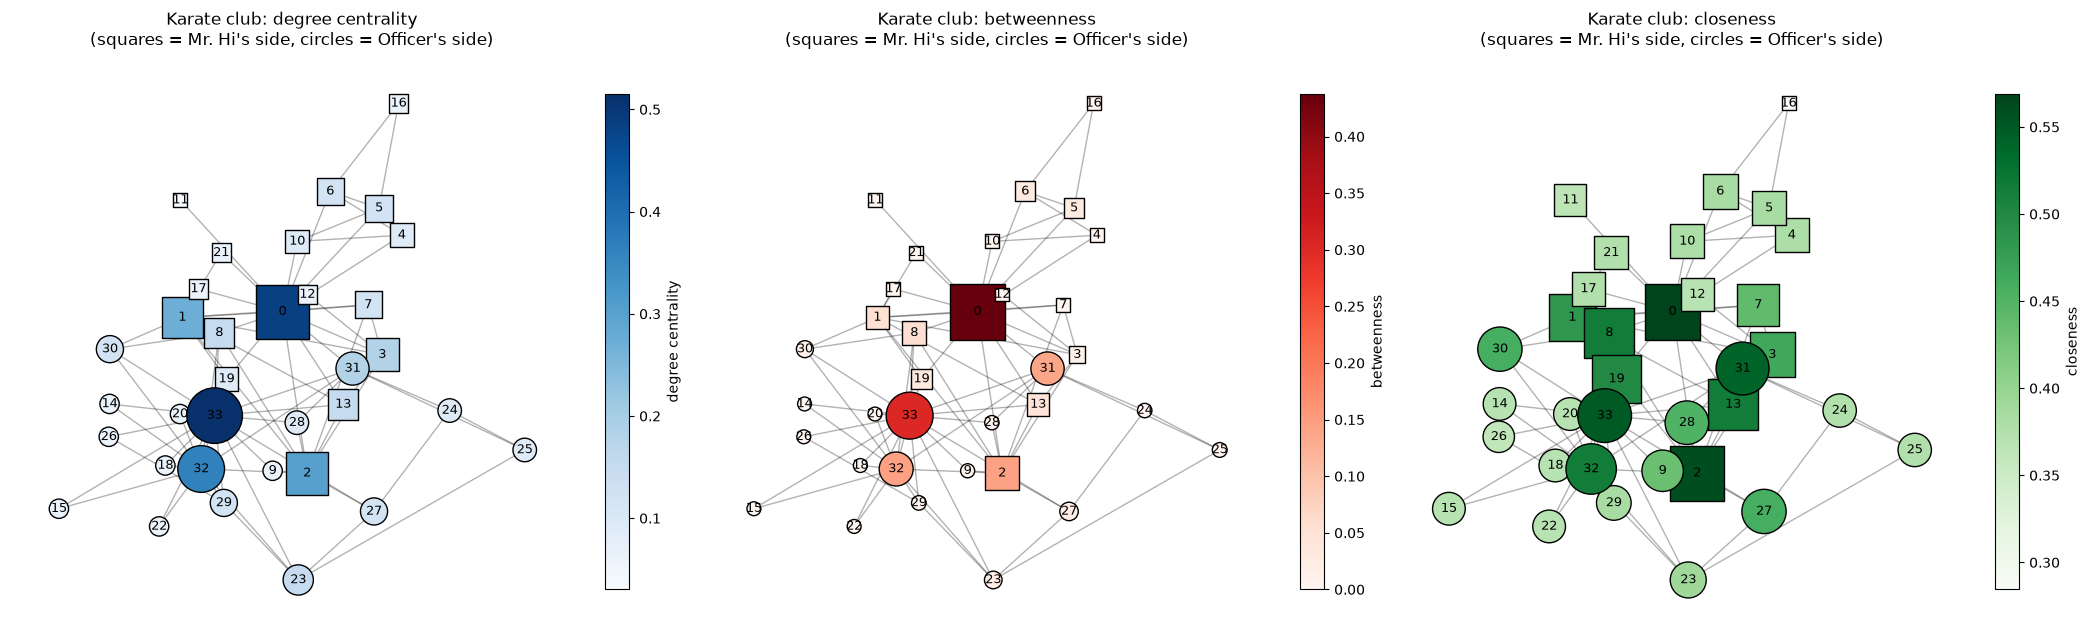

In [45]:
kpos = nx.kamada_kawai_layout(K)
hi = [v for v in K if K.nodes[v]["club"] == "Mr. Hi"]
officer = [v for v in K if K.nodes[v]["club"] == "Officer"]

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, measure, cmap in zip(axes, ["degree centrality", "betweenness", "closeness"], ["Blues", "Reds", "Greens"]):
    vals = kc[measure]
    vmin, vmax = vals.min(), vals.max()
    size = lambda v: 100 + 1500 * (vals[v] - vmin) / (vmax - vmin)
    nx.draw_networkx_edges(K, kpos, ax=ax, alpha=0.3)
    for group_nodes, shape in [(hi, "s"), (officer, "o")]:
        nodes = nx.draw_networkx_nodes(K, kpos, ax=ax, nodelist=group_nodes, node_shape=shape,
                                       node_size=[size(v) for v in group_nodes], node_color=[vals[v] for v in group_nodes],
                                       cmap=cmap, vmin=vmin, vmax=vmax, edgecolors="black")
    nx.draw_networkx_labels(K, kpos, ax=ax, font_size=9)
    plt.colorbar(nodes, ax=ax, fraction=0.04, label=measure)
    ax.set_title(f"Karate club: {measure}\n(squares = Mr. Hi's side, circles = Officer's side)")
    ax.axis("off")
plt.tight_layout()
plt.show()

### 11.4 Do the measures agree?

A scatter plot comparing two measures shows where they agree and, more interestingly, where they disagree.

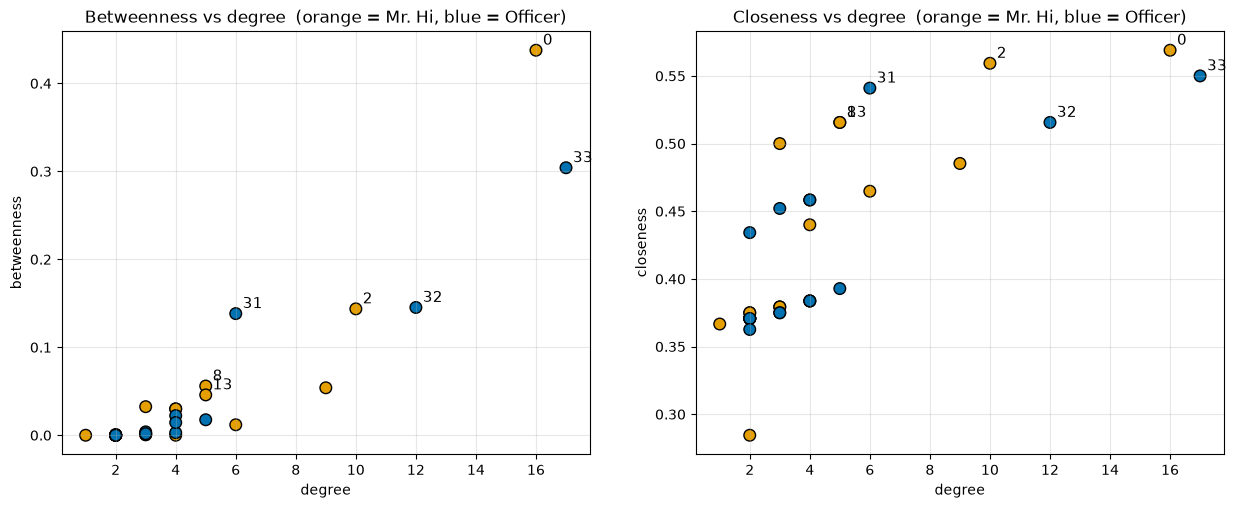

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (x, y) in zip(axes, [("degree", "betweenness"), ("degree", "closeness")]):
    colours = ["#E69F00" if c == "Mr. Hi" else "#0072B2" for c in kc["club"]]
    ax.scatter(kc[x], kc[y], c=colours, s=70, edgecolors="black")
    for v in [0, 33, 32, 2, 31, 8, 13]:     # label the members discussed below
        ax.annotate(v, (kc.loc[v, x], kc.loc[v, y]), xytext=(5, 4), textcoords="offset points", fontsize=11)
    ax.set_xlabel(x); ax.set_ylabel(y); ax.set_title(f"{y.capitalize()} vs {x}  (orange = Mr. Hi, blue = Officer)")
    ax.grid(alpha=0.3)
plt.show()

**What we see.**

* **The two leaders (0 and 33) top almost every measure.** They have the most friends, the most brokerage, and the shortest routes to everyone. That fits the story: the club split around them.
* **The measures don't agree completely.** Member 31 has only 6 friends, half as many as member 32, yet almost the same betweenness. Member 31's friends include Mr. Hi (0) *and* several members of the Officer's side, so many shortest paths between the factions run through 31. Members 2, 8, and 13 likewise have friends on both sides and rank higher on betweenness and closeness than their degree alone would suggest. Being *between* groups is exactly what these path-based measures pick up.
* Closeness values are bunched together, as expected. It's a small, well-connected club where nobody is very far from anybody.

## 12. Summary, glossary, and exercises

### 12.1 The five measures at a glance

| Measure | Network type | How to calculate | Question it answers | High value means… |
|---|---|---|---|---|
| **In-degree** | directed | count arrows pointing **in** (column sum of the adjacency matrix) | Who receives the most ties? | popular, prestigious, much attention received |
| **Out-degree** | directed | count arrows pointing **out** (row sum) | Who sends the most ties? | active, sociable, much attention given |
| **Degree centrality** | both | degree ÷ (n − 1); use in- or out-degree for directed | Who has the most direct contacts? | well-connected locally, visible, exposed |
| **Betweenness centrality** | both | for every pair of other nodes, the share of shortest paths through the node; add up; ÷ (n−1)(n−2)/2 | Who lies between others? | broker, bridge, gatekeeper; removing it disrupts the network |
| **Closeness centrality** | both | (n − 1) ÷ (sum of distances to everyone) | Who can reach everyone fastest? | central position, quick access to the whole network |

The NetworkX commands:

```python
G.degree(n)                     # degree (in + out for directed graphs)
D.in_degree(n), D.out_degree(n) # directed graphs only
nx.degree_centrality(G)         # nx.in_degree_centrality(D), nx.out_degree_centrality(D)
nx.betweenness_centrality(G)    # normalized=False for raw counts
nx.closeness_centrality(G)      # on directed graphs: incoming; use D.reverse() for outgoing
```

### 12.2 Glossary

* **Node (vertex):** an entity in the network (a person, account, airport…).
* **Edge (link, tie):** a connection between two nodes.
* **Undirected / directed network:** edges without / with a direction (lines vs. arrows).
* **Neighbour:** a node directly connected to another node.
* **Degree:** the number of edges touching a node. **In-degree / out-degree:** the number of incoming / outgoing arrows.
* **Path:** a sequence of edges leading from one node to another. **Shortest path:** a path with the fewest edges. **Distance:** the length of the shortest path.
* **Adjacency matrix:** a table with a 1 where two nodes are connected and a 0 otherwise.
* **Centrality:** a family of measures of how "important" or "central" a node is; each defines importance differently.
* **Normalization:** dividing a measure by its largest possible value, so it falls between 0 and 1 and can be compared across networks.
* **Layout:** the choice of where to place nodes in a drawing. It is not part of the data.

### 12.3 Try it yourself

Each exercise has a hidden answer. Click **"Show answer"** after you've tried.

**Exercise 1.** In the follows network, add an edge so that Maya follows Raj back: `follows.add_edge("Maya", "Raj")`. What happens to Raj's in-degree, and to Maya's out-degree? Re-run the cells in Section 6.5 to check.

<details><summary>Show answer</summary>

Raj's in-degree goes from 0 to 1 and Maya's out-degree from 1 to 2. Everyone else is unchanged, because one new arrow changes exactly one in-degree and one out-degree.
</details>

**Exercise 2.** In the study group, suppose Ben and Eva become friends: `friends.add_edge("Ben", "Eva")`. *Before* running any code, predict: does Dee's betweenness go up or down? Then check with `nx.betweenness_centrality(friends)`.

<details><summary>Show answer</summary>

It goes **down**. There is now a second route between the groups (Ben–Eva), so many shortest paths no longer need Dee (or Cai). Dee's betweenness falls from 0.60 to about 0.18, and Cai's from 0.53 to about 0.13. Eva (now about 0.34) and Ben (about 0.22), the two ends of the new bridge, gain betweenness. Remember to remove the edge again afterwards with `friends.remove_edge("Ben", "Eva")`, or simply re-run the cell that built `friends`.
</details>

**Exercise 3.** Calculate by hand the closeness centrality of the centre node of `nx.star_graph(4)` (one centre connected to 4 others) and of one of the outer nodes. Check with NetworkX.

<details><summary>Show answer</summary>

There are $n = 5$ nodes. The centre is 1 step from each of the 4 others: sum = 4, so closeness = 4/4 = **1.0**. An outer node is 1 step from the centre and 2 steps from each of the other 3 outer nodes: sum = 1 + 6 = 7, so closeness = 4/7 ≈ **0.571**. Check with `nx.closeness_centrality(nx.star_graph(4))`.
</details>

**Exercise 4.** In the karate club, which member has the *lowest* betweenness among those with at least 5 friends? What might that mean about their position in the club?

<details><summary>Show answer</summary>

Run `kc[kc["degree"] >= 5].sort_values("betweenness").head()`. Such a member has plenty of friends, but those friends are mostly connected to each other already, so few shortest paths need to pass through them. They are well embedded in one group rather than acting as a bridge.
</details>

### 12.4 Where to go next

* The official NetworkX tutorial: <https://networkx.org/documentation/stable/tutorial.html>
* NetworkX reference for all centrality measures: <https://networkx.org/documentation/stable/reference/algorithms/centrality.html>
* Free online textbook: A.-L. Barabási, *Network Science*, <http://networksciencebook.com/>
* M. E. J. Newman, *Networks* (2nd ed., Oxford University Press, 2018) for a deeper, more mathematical treatment.